# AI SCI 290A Project 1: Weather Prediction
Using ERA5 data

# 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import glob
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 2. Preliminary Exploration

In [2]:
DATA_DIR = "./data/"

In [3]:
temp_files = sorted(
    glob.glob(f"{DATA_DIR}/**/*.nc", recursive=True)
)
ds = xr.open_mfdataset(
    temp_files,
    combine="by_coords"
)


## Avg temp

Text(0.5, 1.0, 'Mean 2m temp')

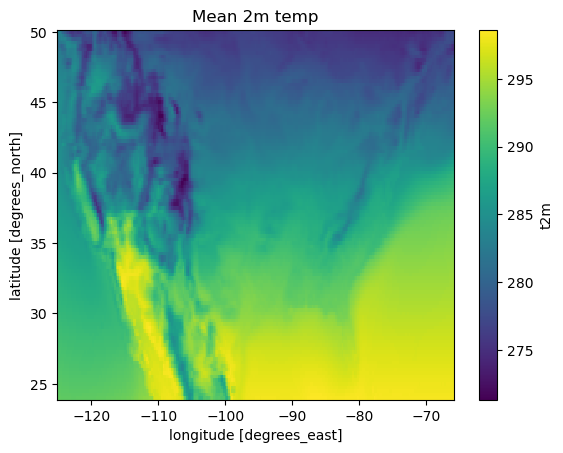

In [4]:
fig, ax = plt.subplots()
ds.t2m.mean(dim="valid_time").plot()
ax.set_title("Mean 2m temp")


## Temperature over time at UC Irvine

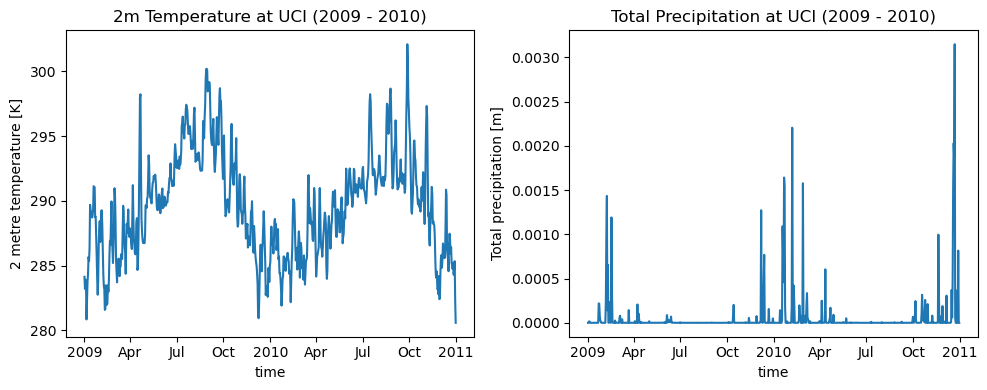

In [5]:
lat_uci = 33.64
lon_uci = -117.84

ds_uci = ds.sel(latitude=lat_uci, longitude=lon_uci, method="nearest")

fig, axs = plt.subplots(
    ncols=2,
    figsize=(10, 4)
)
ds_uci.t2m.plot(ax=axs[0])
axs[0].set_title("2m Temperature at UCI (2009 - 2010)")

ds_uci.tp.plot(ax=axs[1])
axs[1].set_title("Total Precipitation at UCI (2009 - 2010)")

fig.tight_layout()


## Feature Engineering

In [6]:
# Calcs and adds 3 and 7 day rolling average and previous day columns
ds_uci['rolling_3'] = ds_uci['t2m'].rolling(valid_time=3).mean().shift(valid_time=1)  # up to today
ds_uci['rolling_7'] = ds_uci['t2m'].rolling(valid_time=7).mean().shift(valid_time=1)
ds_uci['prev_day'] = ds_uci['t2m'].shift(valid_time=1)  # yesterday's temp


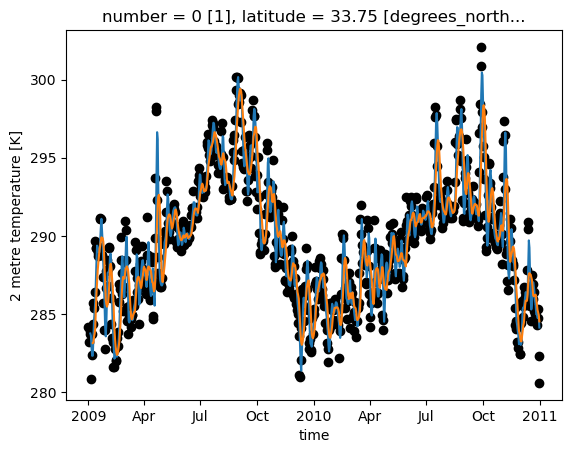

In [7]:
fig, ax = plt.subplots()

ds_uci["t2m"].plot.scatter("valid_time", color="black")
ds_uci["rolling_3"].plot()
ds_uci["rolling_7"].plot()


# 3. Set up ML methods

## Linear Regression
Predicts using a 3-day rolling average, 7-day rolling average, and the previous day's temperature.

In [8]:
def plot_coefs(X, y, model):   
    fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10, 6))

    pred_y = model.predict(X)

    ax1 = ax[0, 0]
    ax1.scatter(pred_y, (pred_y - y))
    ax1.set_ylabel("Residual")
    ax1.set_xlabel("Training Temperature (K)")
    ax1.axhline(y=0, color='red', linestyle='--')

    ax2 = ax[0, 1]
    ax2.scatter(X[:, 0], pred_y)
    ax2.set_xlabel("3-Day Rolling Mean (K)")


    ax3 = ax[1, 0]
    ax3.scatter(X[:, 1], pred_y)
    ax3.set_xlabel("7-Day Rolling Mean (K)")


    ax4 = ax[1, 1]
    ax4.scatter(X[:, 2], pred_y)
    ax4.set_xlabel("Previous Day's Temperature (K)")

    fig.tight_layout()


In [9]:
# Prep for regression by deleting nan rows
ds_uci = ds_uci.dropna(dim="valid_time")
n_samples = len(ds_uci["valid_time"])

### Previous Day

In [10]:
X = ds_uci["prev_day"].values.reshape(-1, 1)
y = ds_uci["t2m"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=222)

reg = LinearRegression()
reg.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


MAE:  0.925
MSE:  1.433
RMSE:  1.197
R²:   0.909


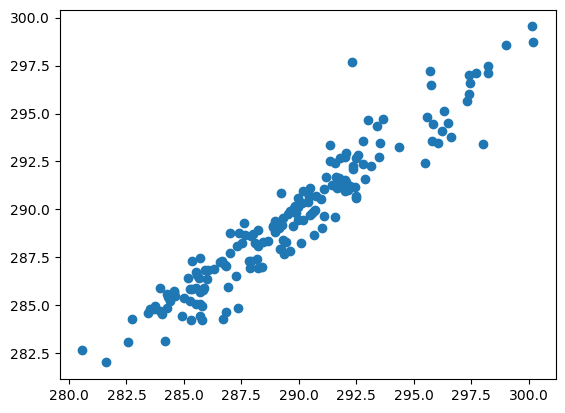

In [11]:
y_pred = reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE:  {rmse:.3f}")
print(f"R²:   {r2:.3f}")

fig, ax = plt.subplots()
ax.scatter(y_test, y_pred)


### 3-Day Rolling Average

In [12]:
X = ds_uci["rolling_3"].values.reshape(-1, 1)
y = ds_uci["t2m"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=222)

reg = LinearRegression()
reg.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


MAE:  1.472
MSE:  3.688
RMSE:  1.921
R²:   0.767


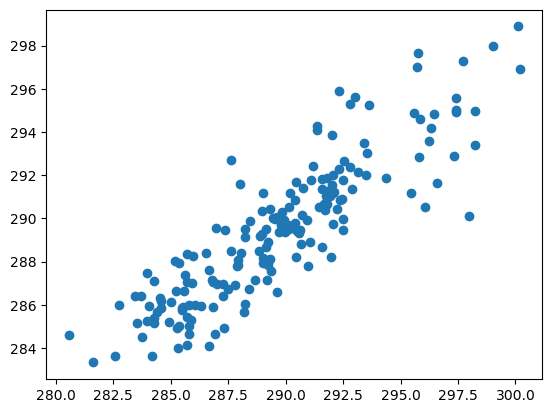

In [13]:
y_pred = reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE:  {rmse:.3f}")
print(f"R²:   {r2:.3f}")

fig, ax = plt.subplots()
ax.scatter(y_test, y_pred)

### 7-Day Rolling Average

In [14]:
X = ds_uci["rolling_7"].values.reshape(-1, 1)
y = ds_uci["t2m"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=222)

reg = LinearRegression()
reg.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


MAE:  1.882
MSE:  6.267
RMSE:  2.503
R²:   0.604


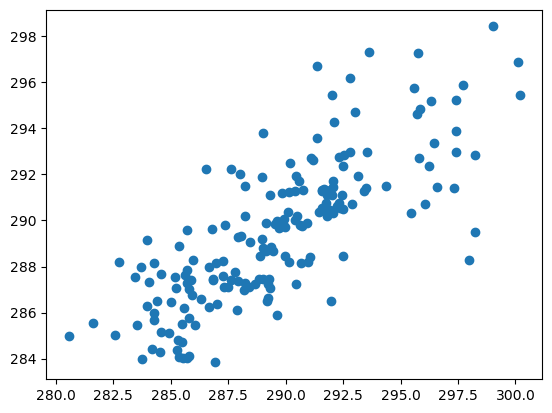

In [15]:
y_pred = reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE:  {rmse:.3f}")
print(f"R²:   {r2:.3f}")

fig, ax = plt.subplots()
ax.scatter(y_test, y_pred)

## All 3

In [42]:
X = ds_uci[["prev_day", "rolling_3", "rolling_7"]]

In [35]:
X = ds_uci[["prev_day", "rolling_3", "rolling_7"]]
y = ds_uci["t2m"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=222)

reg = LinearRegression()
reg.fit(X_train, y_train)

ValueError: Found input variables with inconsistent numbers of samples: [3, 723]

MAE:  1.882
MSE:  6.267
RMSE:  2.503
R²:   0.604


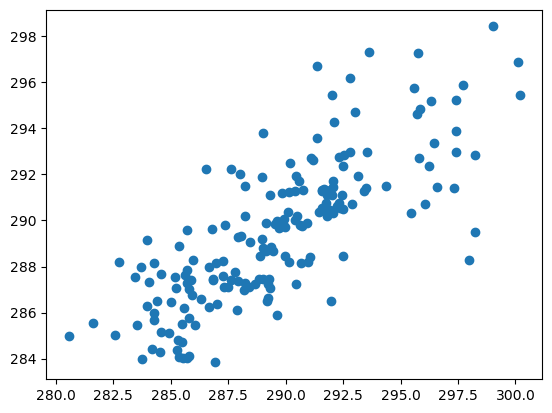

In [30]:
y_pred = reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE:  {rmse:.3f}")
print(f"R²:   {r2:.3f}")

fig, ax = plt.subplots()
ax.scatter(y_test, y_pred)